# 19. Photographs, rays and COLMAP cameras

[Course plan](../../README.md)

Two photographs of a sculpture look almost identical. In one, a stone edge hides a patch of background. In the other, a sliver opens between them. Small shifts like this reveal depth. A blank patch of wall contributes little until we can identify the same location in another frame.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'

import photo_diagnostics as inspect_photo

## Two cameras at a table

A tabletop setup isolates the geometry. The optical axes are parallel and the second camera sits 40 cm to the right of the first. Their separation B is the baseline. The orange ray passes through the mark in the right image and the blue through the mark in the left. Both rays lie in one horizontal plane. A small pixel error shifts their intersection. In the top view, depth increases away from the cameras.


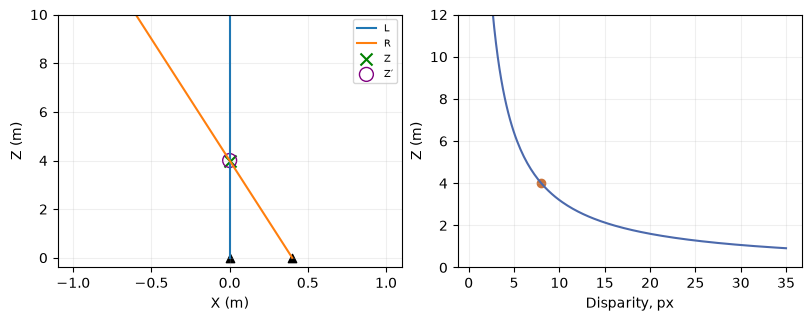

In [2]:
display(rays_figure(lang=lang)); plt.close()
controls(lambda B, du, Z: rays_figure(B, du, Z, lang),
         B=(0,1,.01,.4), du=(-4,4,.1,0), Z=(1,8,.1,4))


## What changes when the camera goes around the subject?

There are two plausible explanations for a single photograph. In the first, a red mark is two metres in front of the lens. In the second it is six metres away. Both lie on the optical axis and land in column 40. If the farther mark is three times as wide in the world, even its outline can match the nearer one. A perfectly sharp contour in a single photograph still leaves depth open.

The camera now moves 40 cm to the right without turning. Relative to the camera, the mark moves 40 cm to the left. The near mark shifts by $80\cdot(-0.4)/2=-16$ pixels. For the far one the shift is $80\cdot(-0.4)/6\approx-5.33$. The first images agreed; the two predictions for the second are over ten pixels apart. This shift is parallax. It supplies a second measurement that depends on depth.

Turning the lens in place also changes the pixel address. But the line in the world from the camera center to the mark stays put. Any point farther along it is still consistent with both views. Images can look very different and yet give weak geometry. What matters during capture is the path of the camera **center**. The perspective calculation also needs the orientation of its axes.

<details><summary>Which second exposure distinguishes the two distances?</summary>

With a 0.1 m baseline the predicted positions differ by $80\cdot0.1(1/2-1/6)\approx2.67$ pixels. With 0.4 m they differ by about 10.67 pixels. A one-pixel marking error consumes a much larger fraction of the first separation. The longer baseline helps while the same detail remains visible and recognizable in both views.

</details>

## Eight pixels become four meters

Let $X$ be the target’s rightward offset from the left camera in meters, and $Z$ its forward distance in meters. Focal length $f$ is measured in pixels. The principal point has horizontal coordinate $c_x$. In the right camera the same target is at $X-B$. The recorded image columns are $u_L,u_R$.

$$
u_L=c_x+fX/Z,\qquad u_R=c_x+f(X-B)/Z.
$$

Subtracting the right column from the left cancels the shared $c_x$. The numerator contains $X-(X-B)=B$. The column difference $d=u_L-u_R$ is called disparity. This gives $d=fB/Z$. Multiplying by $Z$ and dividing by $d$ isolates depth, $Z=fB/d$.

Here $f=80$ pixels, $B=0.4$ m, $X=0$, $c_x=40$, and $Z=4$ m. The left column is 40 and the right is $40+80(0-0.4)/4=32$. Their difference is $40-32=8$ pixels. Depth is $80\cdot0.4/8=4$ m. The pixel units cancel. Moving the right mark one pixel to the right makes $d=7$ and puts the target at $32/7\approx4.57$ m. At $B=0$ both rays start at the same point, so one mark cannot determine depth. With nonzero baseline and $d=0$, there is no finite intersection in this setup.

Cameras on a walk around an object also rotate. Each image mark then defines a ray from its own camera center in a direction determined by that camera’s parameters. Noise can make two rays miss one another. Reconstruction looks for a 3D point whose **projections** lie near the recorded marks across several images.


In [3]:
for B, shift in [(.4,0), (.4,1), (.05,0), (.05,1)]:
    uL, uR = 40, 40-80*B/4+shift
    print(B, shift, "→", triangulate(80,B,uL,uR))
assert triangulate(80,.4,40,32) == 4


0.4 0 → 4.0
0.4 1 → 4.571428571428571
0.05 0 → 4.0
0.05 1 → None


## How much depth fits inside a pixel?

It is tempting to read 4.57 m as a new distance to the object. Yet the mark on the table did not move. Only the observation changed. A better question starts with the measured disparity of eight pixels. Which depths would agree if that difference could be off by one pixel? At the near end $d=9$ gives $Z=32/9\approx3.56$ m. At the far end $d=7$ gives $Z=32/7\approx4.57$ m. The interval is asymmetric about 4 m because the uncertain measurement sits in the denominator.

At a depth of 8 m, the same baseline produces a disparity of only four pixels. Disparities from three to five now imply depths from $32/5=6.4$ to $32/3\approx10.67$ m. The lens and the accuracy of the pencil mark have stayed the same. The subject's distance changed what we can infer. If each individual observation can be off by one pixel, two errors in opposite directions can change their **difference** by two pixels.

<details><summary>The disparity is two pixels and its error could also be two. Where is the far end?</summary>

The near end has a disparity of four and a depth of 8 m. At the other end the disparity approaches zero from above. The quotient has no finite upper bound. A distance of 16 m corresponds to the middle of the measured pixel interval. It conveys very little about the uncertainty in metres.

</details>

d = 8 px:  Z = 4.00 m,  [3.56, 4.57] m
d = 4 px:  Z = 8.00 m,  [6.40, 10.67] m
d = 2 px:  Z = 16.00 m,  [10.67, 32.00] m


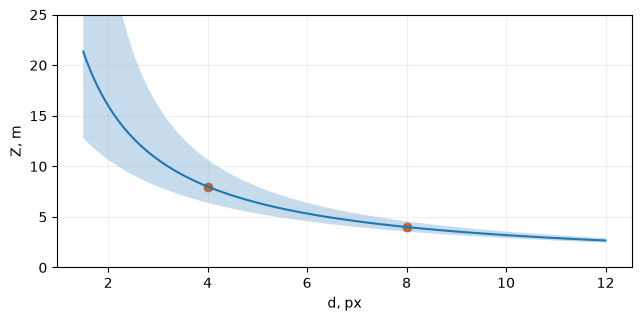

In [4]:
for d in (8, 4, 2):
    near, far = 32/(d+1), 32/(d-1)
    print(f"d = {d} px:  Z = {32/d:.2f} m,  [{near:.2f}, {far:.2f}] m")
disparities = np.linspace(1.5, 12, 150)
fig, ax = plt.subplots(figsize=(6.3, 3.1), layout="constrained")
ax.fill_between(disparities,32/(disparities+1),32/(disparities-1),alpha=.25)
ax.plot(disparities,32/disparities)
ax.scatter([4,8],[8,4],color="#b36639")
ax.set(xlabel="d, px",ylabel="Z, m",ylim=(0,25))
ax.grid(alpha=.2)
plt.show()

## What goes into a capture

Small camera steps keep recognizable fine details in neighboring photographs. A static matte object, diffuse light and sharp exposures make corresponding points easier to recognize. A second arc at another height opens up the top surface. Rotating the camera in place changes its direction while barely moving its center. The rays then constrain depth poorly. Very large steps lose shared details. Glass, a pedestrian, a repeated ornament or a highlight can produce convincing matches that belong to different world points.

Motion blur erases distinctive corners. Automatic exposure can turn the same wall from dark to light between frames. A small reprojection error on visible points says little about an unseen back surface. Before training we can already inspect both the images and the camera locations.


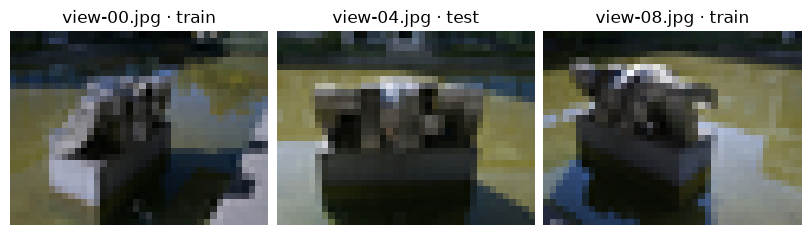

train: 8 test: 1


In [5]:
frames, seeds = photo_capture()
fig, axes = plt.subplots(1,3,figsize=(8,2.8),layout="constrained")
for ax, index in zip(axes,[0,4,8]):
    f=frames[index]
    ax.imshow(f["rgb"]); ax.set_title(f["name"]+" · "+f["split"]); ax.axis("off")
plt.show()
print("train:", sum(f["split"]=="train" for f in frames), "test:", sum(f["split"]=="test" for f in frames))


## Inside a sparse reconstruction

Nine small real photographs of **struktur28_auto** from PhysicalAI-NuRec-PPISP (NVIDIA Corporation, CC BY 4.0) are included with the course. Their intrinsic and extrinsic camera parameters are known. The cloud contains points. A point can have a track listing the images and 2D observation indices where it was recognized. The middle image view-04 is reserved for image evaluation. Camera poses are provided for the complete set, so this experiment measures image synthesis at a **known pose**. The [photograph notes](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example) document the source, license and transformations.

In a COLMAP text export, **cameras.txt** identifies the lens model. PINHOLE stores width, height and $f_x,f_y,c_x,c_y$. In **images.txt**, the first row of each image gives quaternion $(w,x,y,z)$, translation $t$, camera ID and filename. The next row stores triples of pixel x, pixel y and 3D point ID. ID −1 marks an observation with no reconstructed point. **points3D.txt** associates point IDs with position, RGB, error and track. ID 93 need not be row number 93.

COLMAP stores the **world-to-camera** transform $p_c=R p_w+t$. The camera center has zero coordinates in its own frame. Substitution gives $0=R C+t$. Moving $t$ across and undoing the rotation yields $C=-R^T t$. With an identity rotation and $t=(-0.4,0,0)$, the camera stands at $(+0.4,0,0)$. This often accounts for a sign error. Our renderer stores $C$ and the **camera-to-world** rotation $R^T$.

COLMAP’s first pixel center is $(0.5,0.5)$, while the first array sample here is $(0,0)$. Resizing width 160 to 40 uses $s=40/160=0.25$. The new focal length is $f'_x=s f_x$ and the principal point becomes $c'_x=s c_x-0.5$. Starting from $c_x=80$ gives 19.5, halfway between 19 and 20. Vertical coordinates use the actual ratio of heights after rounding. Shrinking only the image without updating $f_x$ would move its predicted pixels.


In [6]:
cam = frames[0]["camera"]
R = np.array(cam["rotation"]).T  # world to camera
C = np.array(cam["center"])
t = -R @ C
assert np.allclose(-R.T @ t, C)
print("C:", C.round(3), "f:", np.round(cam["focal"],3), "c:", cam["principal"])

# A measured feature and its projection in the original (160 x 120) training view.
from reconstruction_demos import ROOT
from geometry3d import project_point, quaternion_matrix
model_dir = ROOT / "data/photographic-example/sparse/0"
rows = [line for line in (model_dir/"images.txt").read_text().splitlines() if not line.startswith("#")]
header = rows[0].split()
observation = rows[1].split()
u, v, point_id = float(observation[0]), float(observation[1]), observation[2]
point_rows = (model_dir/"points3D.txt").read_text().splitlines()
point = next(line.split() for line in point_rows if line and line.split()[0] == point_id)
X = np.array(point[1:4],float)
world_to_cam = quaternion_matrix([float(v) for v in header[1:5]])
t0 = np.array(header[5:8],float)
intrinsics = next(line.split() for line in (model_dir/"cameras.txt").read_text().splitlines()
                  if line and not line.startswith("#"))
fx, fy, cx, cy = map(float,intrinsics[4:])
observed = np.array([u-.5,v-.5])
camera_point = world_to_cam @ X + t0
pred = project_point(camera_point,[fx,fy],[cx-.5,cy-.5])
wrong = project_point(camera_point+[.08,0,0],[fx,fy],[cx-.5,cy-.5])
print("point ID", point_id, "observed:", observed.round(3), "projected:", pred.round(3))
print("reprojection error (px):",round(np.linalg.norm(pred-observed),3),
      "after translation:",round(np.linalg.norm(wrong-observed),3))


C: [-0.528  0.407 -4.51 ] f: [42.363 42.705] c: [19.5, 14.5]
point ID 26 observed: [ 30.667 113.767] projected: [ 30.989 113.992]
reprojection error (px): 0.393 after translation: 4.012


The preceding calculation uses a real observed feature in the first photograph. Its ID connects two measured image coordinates to a 3D point. A world-to-camera transform and projection predict a pixel. Adding 0.08 scene units to the camera transform’s horizontal translation deliberately moves this prediction away from the observation. The final line reports both error lengths in pixels.

## Following one feature through three files

Some edges on the sculpture meet in dark corners that are easy to recognize. A detector picks out a local feature and describes the appearance around it numerically. Matching looks for similar descriptions. Two windows on the same building may look almost identical, so a descriptor match is only a candidate. If most matches agree with one relative camera pose and a pair lands somewhere completely different, geometric verification can reject that pair. Even the survivors are worth examining on the photographs.

An image takes up two lines in `images.txt`. The first identifies its file, camera and pose. The second repeats triples of horizontal coordinate, vertical coordinate and point ID. In a standard export, a negative ID denotes an observation without a reconstructed 3D point. In the other direction, `points3D.txt` identifies the images and observation indices in which each point was seen. An ID can be 148 even if there are only 117 points. Filtering leaves gaps. Reading the 148th row would be a mistake.

Point 148 has four observations in this capture. Two locate a point in space. A third lets us see where it lands. The experiment below uses images 80 pixels wide. In the original file for a 160-pixel image, coordinates are measured from the left edge. For example, $u=100.08$ becomes $100.08\cdot80/160-0.5=49.54$ in array coordinates. Subtracting half a pixel moves the origin from the pixel edge to its center. The way back to full-resolution file coordinates adds the half first and then divides by the scale. Reversing those operations changes the answer.

In the enlarged patches the orange cross is an observation; the blue ring is the projection of the reconstructed point. Moving the second cross horizontally changes the reconstruction. The cross in image 07 stays put. That image is reserved **for checking this pair of rays**. It did take part in estimating the full sparse model. The photograph `view-04` remains reserved for a different experiment, evaluating the trained scene.

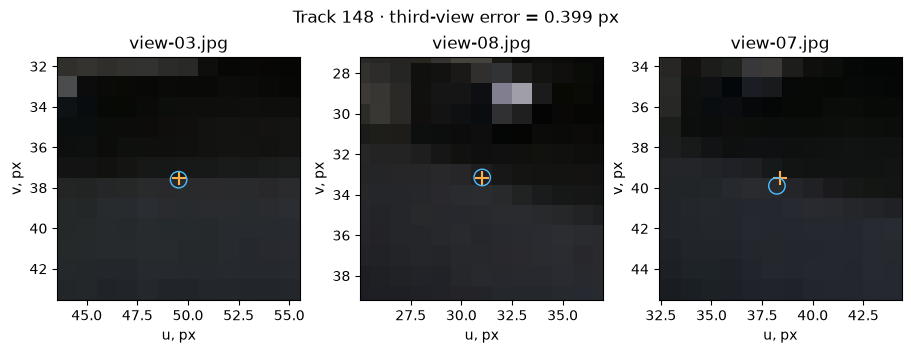

In [7]:
views80, _ = photo_capture(max_side=80)
track = inspect_photo.feature_track()
display(inspect_photo.track_figure(views80,track,lang=lang)); plt.close()
controls(lambda partner, offset: inspect_photo.track_figure(views80,track,partner,offset,lang),
         partner=[8,6], offset=(-3,3,.1,0))

## From a mark to a ray and back to a mark

The first image provides $(u,v)$. Subtracting $(c_x,c_y)$ measures the offset from the optical axis. Dividing the horizontal difference by $f_x$ and the vertical one by $f_y$ gives the offsets **one camera unit forward**. Together with that forward unit they form a direction, $((u-c_x)/f_x,(v-c_y)/f_y,1)$. Its length is arbitrary. At depth two all three numbers could double and still give the same pixel. Multiplying by the camera orientation expresses the direction in the world. Dividing by its length leaves a unit arrow.

The first camera stands at $A$, the second at $B$, with unit arrows $r$ and $s$. Traveling a distance $a$ along the first ray reaches $A+ar$. The second gives $B+bs$, with its own travel distance $b$. Perfect observations would put both expressions at the same point. Moving the known terms across gives $ar-bs=B-A$. On the left, two known directions have unknown lengths. On the right is the known vector between the camera centers. Three coordinates yield three equations. Noise usually prevents two lengths from satisfying all three simultaneously.

The `lstsq` call chooses lengths that minimize the sum of the three squared discrepancies. The resulting points are the closest points on the two lines. Their midpoint supplies a hypothesis that we can project into image 07. This construction is simple enough to check by hand. When COLMAP refines a model, it minimizes errors **in the images** rather than distances between pairs of lines in the world.

For images 03 and 08 with zero offset, the third cross is near $(38.392,39.528)$ and the prediction is $(38.231,39.894)$. The distance is $\sqrt{(-0.161)^2+0.366^2}\approx0.40$ pixel. Shifting the second mark by three pixels increases it to about 2.01 pixels. With images 03 and 06 the same shift gives about 3.44. The real photographs are more complicated than parallel cameras at a table. Both camera orientations and the direction of the marking error matter.

<details><summary>Can a zero gap between two rays still produce the wrong point?</summary>

Yes. A wrong match in the right image might land farther along the same epipolar line, the set of possible projections of the left ray. The rays can literally intersect, just at a different depth. A third image from another position checks that false intersection. Agreement in local appearance across all three images lends further support.

</details>

In [8]:
by_name = {frame["name"]: frame for frame in views80}
a, c = by_name["view-03.jpg"], by_name["view-07.jpg"]
for second in ("view-06.jpg", "view-08.jpg"):
    b = by_name[second]
    for offset in (0., 1., 3.):
        p, gap = inspect_photo.intersect_observations(
            a, inspect_photo.measured_pixel(track,a), b, inspect_photo.measured_pixel(track,b)+[offset,0])
        miss = inspect_photo.reproject(p,c)-inspect_photo.measured_pixel(track,c)
        print(f"{second}: Δu={offset:.0f} px   gap={gap:.4f}   ||Δuv₇||={np.linalg.norm(miss):.3f} px")

view-06.jpg: Δu=0 px   gap=0.0113   ||Δuv₇||=0.452 px
view-06.jpg: Δu=1 px   gap=0.0144   ||Δuv₇||=1.197 px
view-06.jpg: Δu=3 px   gap=0.0689   ||Δuv₇||=3.437 px
view-08.jpg: Δu=0 px   gap=0.0048   ||Δuv₇||=0.399 px
view-08.jpg: Δu=1 px   gap=0.0160   ||Δuv₇||=0.622 px
view-08.jpg: Δu=3 px   gap=0.0590   ||Δuv₇||=2.013 px


## A new set of photographs

For a static scene the detector first finds image features. Matching proposes pairs and geometric verification rejects inconsistent matches. The mapper registers cameras, triangulates points and refines camera and point parameters jointly against reprojection errors. An error here is the distance from the observed pixel to its predicted location. An offset of 3 pixels horizontally and 4 vertically has length √(9+16) = 5 pixels.

The commands below use an installed COLMAP. The raw photos are in capture/input; the empty capture/sparse and capture/text directories already exist. `exhaustive_matcher` considers all image pairs, which suits a small collection. If mapping produces several disconnected components, the example’s directory 0 stands for the connected model containing the relevant views.

```sh
colmap feature_extractor --database_path capture/database.db --image_path capture/input
colmap exhaustive_matcher --database_path capture/database.db
colmap mapper --database_path capture/database.db --image_path capture/input --output_path capture/sparse
colmap image_undistorter --image_path capture/input --input_path capture/sparse/0 --output_path capture/undistorted --output_type COLMAP
colmap model_converter --input_path capture/undistorted/sparse --output_path capture/text --output_type TXT
```

The course loader now reads `capture/text` and `capture/undistorted/images`. The undistorted model matters because our camera implements perspective division alone. A distorted photograph and an ideal pinhole camera disagree most near the edges. A large capture can be downsampled for a small experiment. The loader handles image resampling and camera scaling together.

[COLMAP commands](https://colmap.github.io/cli.html) · [Model format](https://colmap.github.io/format.html) · [Capture and reconstruction](https://colmap.github.io/tutorial.html)

## An experiment

Two reconstructions have the same mean reprojection error. In one the cameras barely move; in the other they follow an arc around the subject. Do they determine depth equally well?

<details><summary>Worked answer</summary>

In the first capture, moving a point along the viewing ray hardly changes its image. A small image error can coexist with large depth uncertainty. The second capture intersects rays from different directions and constrains the position more tightly. Track lengths, camera layout and the photographs help explain the difference.

</details>


## What can be fixed before the first Gaussian appears?

The sparse model now exists. One meaningful count is how many **distinct views** observe a feature. Two observations give a pair of rays. A third adds an independent place where the point should land. But ten exposures taken almost in place still give a weak intersection. Track lengths make sense alongside camera positions and coverage of the subject. In this capture, 79 of the 117 points have exactly three observations. That describes the connections in the data. It cannot establish that the top of the sculpture or the space behind it has been recovered.

There is another freedom that is invisible in the photographs. Doubling the camera baselines and the world geometry doubles both horizontal offsets and depths. The ratio $X/Z$ stays the same. Measuring the statue in centimetres requires a known dimension, a measured baseline or some other external scale. That is why the baseline at the table is in metres while the gap in the photographic experiment is in reconstruction units.

<details><summary>Only 12 of 40 photographs registered, yet those twelve have a small error. What is worth examining before training?</summary>

The names and positions of the registered images come first. If they cover only the front arc, the small error describes the features visible from the front. Shared tracks at the end of that arc come next. A gap between the last sharp side view and a distant rear view can leave two disconnected models. A few overlapping photographs between arcs supply information that more training iterations cannot add. If matches do exist but consistent directional errors remain near every image edge, the lens model or an inconsistent resize is a better suspect.

</details>

Three things move on to the next lesson: the images, the cameras in a common coordinate system and the sparse colored points. An empty patch in the cloud only means that no reliable track was recovered there. Some gaps can still be filled during training if the cameras actually see the region.